# A simple conditional graph with langgraph

In [17]:
from dotenv import load_dotenv

load_dotenv()

from typing import TypedDict

from langgraph.graph import END, START, StateGraph


class AgentState(TypedDict):
    number1: int
    number2: int
    number3: int
    number4: int
    operation1: str
    operation2: str
    result1: int | None
    result2: int | None

def add_node1(state: AgentState) -> AgentState: 
    '''Add num1 and num2 in state'''

    state['result1'] = state['number1'] + state['number2']

    return state


def sub_node1(state: AgentState) -> AgentState: 
    '''Subtract num1 and num2 in state'''

    state['result1'] = state['number1'] - state['number2']

    return state

def route_operation1(state: AgentState): 
    if state['operation1'] == '+':
        return 'add_node1_edge'
    else:
        return 'sub_node1_edge'


def add_node2(state: AgentState) -> AgentState: 
    '''Add num3 and num4 in state'''

    state['result2'] = state['number3'] + state['number4']

    return state


def sub_node2(state: AgentState) -> AgentState: 
    '''Subtract num3 and num4 in state'''

    state['result2'] = state['number3'] - state['number4']

    return state

def route_operation2(state: AgentState): 
    if state['operation2'] == '+':
        return 'add_node2_edge'
    else:
        return 'sub_node2_edge'


graph = StateGraph(AgentState)

graph.add_node('router1', lambda state:state)
graph.add_node('router2', lambda state:state)

graph.add_node('add_node1', add_node1)
graph.add_node('add_node2', add_node2)
graph.add_node('sub_node1', sub_node1)
graph.add_node('sub_node2', sub_node2)

graph.add_edge(START, 'router1')

graph.add_conditional_edges(
    'router1',
    route_operation1,
    {
        "add_node1_edge": "add_node1",
        'sub_node1_edge': "sub_node1"

    }
)

graph.add_edge('add_node1', 'router2')
graph.add_edge('sub_node1', 'router2')

graph.add_conditional_edges(
    'router2',
    route_operation2,
    {
        "add_node2_edge": "add_node2",
        'sub_node2_edge': "sub_node2"

    }
)

graph.add_edge('add_node2', END)
graph.add_edge('sub_node2', END)

agent = graph.compile()



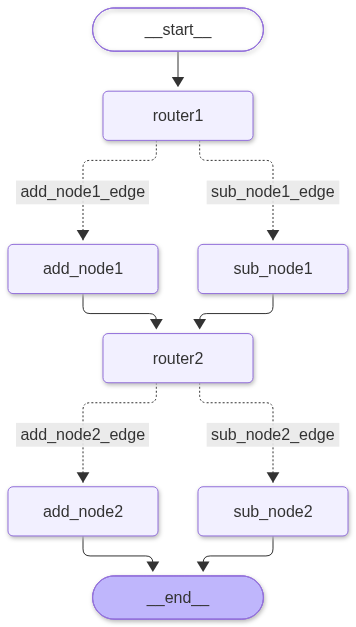

In [15]:
from IPython.display import Image, display

display(Image(agent.get_graph().draw_mermaid_png()))

In [18]:
result = agent.invoke({'number1': 2, 'number2': 4, 'operation1': '+', 'number3': 6, 'number4': 8, 'operation2': '-', 'result1': None, 'result2': None})

result

{'number1': 2,
 'number2': 4,
 'number3': 6,
 'number4': 8,
 'operation1': '+',
 'operation2': '-',
 'result1': 6,
 'result2': -2}